# Churn Labels and Snapshots

**Goal:** decide who is scored, and whether each customer churned, for every snapshot date.
**Input:** `sales.parquet` from `01_data_cleaning.ipynb`. **Output:** `labels.parquet`.

## Setup and load the cleaned data

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Folder where the charts are saved (they are used in the README)
fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

sales = pd.read_parquet("../data/processed/sales.parquet")
sales["line_total"] = sales["quantity"] * sales["price"]

# One row per invoice (one purchase = one invoice)
invoices = (
    sales.groupby(["customer_id", "invoice"])
    .agg(invoice_date=("invoicedate", "min"), revenue=("line_total", "sum"))
    .reset_index()
)

print("Invoices:", f"{len(invoices):,}", "| Customers:", f"{invoices['customer_id'].nunique():,}")
print("Data from", invoices["invoice_date"].min().date(), "to", invoices["invoice_date"].max().date())

Invoices: 36,480 | Customers: 5,851
Data from 2009-12-01 to 2011-12-09


## Are there long periods with no invoices (holiday closure)?

In [2]:
# Number of invoices on every calendar day
daily = invoices.set_index("invoice_date")["invoice"].resample("D").nunique()

# Mark runs of consecutive days with no invoice at all
calendar = daily.rename("n").reset_index()
calendar["no_invoice"] = calendar["n"] == 0
calendar["run"] = (calendar["no_invoice"] != calendar["no_invoice"].shift()).cumsum()

# Start, end and length of every run of days without invoices
runs = calendar[calendar["no_invoice"]].groupby("run").agg(start=("invoice_date", "min"), end=("invoice_date", "max"), days=("n", "size"))

# The 5 longest periods without invoices
runs.sort_values("days", ascending=False).head(5)

,start,end,days
run,,,
6,2009-12-24,2010-01-03,11
114,2010-12-24,2011-01-03,11
146,2011-04-22,2011-04-25,4
32,2010-04-02,2010-04-05,4
148,2011-04-29,2011-04-30,2


## Define the churn rule and the snapshot dates

**Design:** a *snapshot* is one cutoff date. For every customer who was active before it, the label says whether they bought in the next 90 open days.

- **Train:** one snapshot every 30 days from Jun 2010 to Mar 2011. **Valid:** 12 Jun 2011. **Test:** 10 Sep 2011.
- Days when the shop was closed for a week or more (Christmas) do not count towards the 90 days.
- Every label window ends before the next period starts, so nothing from the future leaks into an earlier period.

In [3]:
# Churn rule: a customer churns if they make NO purchase in the next 90 days the shop was open
label_days = 90

# Only score customers who were still "alive": at least one purchase in the 180 days before the cutoff
active_days = pd.Timedelta(days=180)

# Open days: every day except the closed periods (7 or more days in a row without any invoice)
closed_runs = runs[runs["days"] >= 7].index
open_days = calendar.loc[~calendar["run"].isin(closed_runs), "invoice_date"]
print("Closed days found:", calendar["run"].isin(closed_runs).sum())

# Snapshot dates (cutoffs), in time order
snapshots = {
    "train": list(pd.date_range("2010-06-14", "2011-03-14", freq="30D")),   # one every 30 days
    "valid": [pd.Timestamp("2011-06-12")],
    "test": [pd.Timestamp("2011-09-10")],
}

Closed days found: 22


## Build the churn label for every snapshot

In [4]:
parts = []

for split, cutoffs in snapshots.items():
    for cutoff in cutoffs:
        # The label window ends after the 90th OPEN day (closed days do not count)
        label_end = open_days[open_days >= cutoff].iloc[label_days - 1] + pd.Timedelta(days=1)

        # PAST: customers with at least one purchase in the 180 days before the cutoff
        past = invoices[invoices["invoice_date"] < cutoff]
        active = past[past["invoice_date"] >= cutoff - active_days]["customer_id"].unique()

        # FUTURE: purchases inside the label window (used ONLY to make the label)
        future = invoices[(invoices["invoice_date"] >= cutoff) & (invoices["invoice_date"] < label_end)]

        snap = pd.DataFrame({"customer_id": active})
        snap["cutoff"] = cutoff
        snap["split"] = split
        snap["churn"] = (~snap["customer_id"].isin(future["customer_id"])).astype("int8")   # 1 = no purchase in the label window
        parts.append(snap)

        print(split, cutoff.date(), "| label window:", (label_end - cutoff).days, "days")

labels = pd.concat(parts, ignore_index=True)

train 2010-06-14 | label window: 90 days
train 2010-07-14 | label window: 90 days
train 2010-08-13 | label window: 90 days
train 2010-09-12 | label window: 90 days
train 2010-10-12 | label window: 101 days
train 2010-11-11 | label window: 101 days
train 2010-12-11 | label window: 101 days
train 2011-01-10 | label window: 90 days
train 2011-02-09 | label window: 90 days
train 2011-03-11 | label window: 90 days
valid 2011-06-12 | label window: 90 days
test 2011-09-10 | label window: 90 days


## Check the churn rate of every snapshot

       cutoff  split  customers  churn_rate
0  2010-06-14  train       2621       0.507
1  2010-07-14  train       2788       0.469
2  2010-08-13  train       2825       0.406
3  2010-09-12  train       2819       0.382
4  2010-10-12  train       3014       0.440
5  2010-11-11  train       3261       0.527
6  2010-12-11  train       3472       0.626
7  2011-01-10  train       3377       0.611
8  2011-02-09  train       3361       0.594
9  2011-03-11  train       3347       0.577
10 2011-06-12  valid       2629       0.503
11 2011-09-10   test       2783       0.383


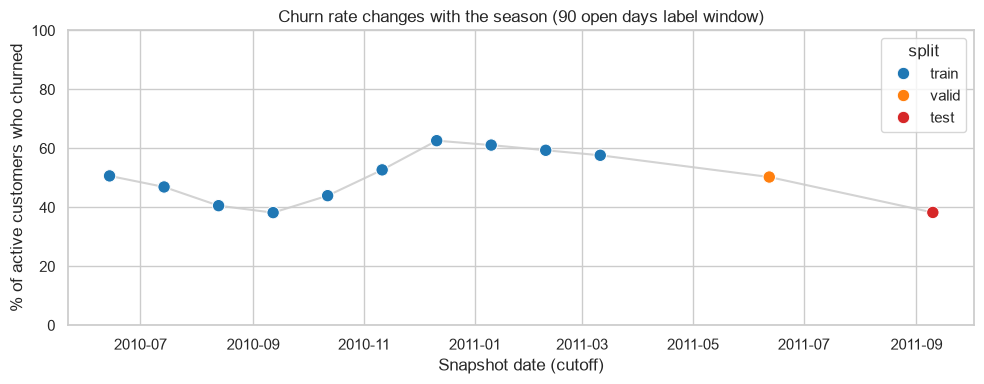

,rows,customers,churn_rate
split,,,
test,2783,2783,0.383
train,30885,4484,0.520
valid,2629,2629,0.503


In [5]:
# Customers and churn rate of every snapshot
summary = labels.groupby(["cutoff", "split"], as_index=False).agg(customers=("customer_id", "count"), churn_rate=("churn", "mean"))
print(summary.round({"churn_rate": 3}))

# Chart: churn rate of every snapshot over time
plt.plot(summary["cutoff"], summary["churn_rate"] * 100, color="lightgrey", zorder=0)
sns.scatterplot(x=summary["cutoff"], y=summary["churn_rate"] * 100, hue=summary["split"], s=80,
                palette={"train": "tab:blue", "valid": "tab:orange", "test": "tab:red"})
plt.title("Churn rate changes with the season (90 open days label window)")
plt.xlabel("Snapshot date (cutoff)")
plt.ylabel("% of active customers who churned")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(fig_dir / "churn_rate_by_snapshot.png", dpi=150, bbox_inches="tight")
plt.show()

# Rows, customers and churn rate for each split
labels.groupby("split").agg(rows=("churn", "size"), customers=("customer_id", "nunique"), churn_rate=("churn", "mean")).round(3)

## Save the labels

In [6]:
labels.to_parquet("../data/processed/labels.parquet", index=False)
print("Saved labels:", f"{len(labels):,}", "rows")

Saved labels: 36,297 rows
